# Swin-T for dog breed classification: two-phase transfer learning

ITRI626 group project, **model family 3 of 3: Swin Transformer** (Sulaiman).
The other two models are Lindani's CNN trained from scratch and JP's
EfficientNetV2-S.

This notebook shows the two runs trained with **JP's pipeline**, so the three
pretrained/fine-tuned results are directly comparable:

| Run | Split file | Classes | What it tests |
|---|---|---|---|
| `unclean_transfer` | `JP_Model/split_manifest.json` | 120 | the dataset as downloaded |
| `simplified_transfer` | `JP_Model/split_manifest_simplified.json` | 114 | duplicates and label conflicts removed, 4 look-alike groups merged |

Training and testing were run from the terminal (`train.py`, `evaluate.py`,
commands in `README.md`). This notebook reads what those scripts wrote to
`results/runs/` and shows it, so every number here comes from a file.

The earlier 85 % run, trained with a different (Lindani-based) pipeline, is
kept separately in `previous_run_lindani_pipeline/` and only appears below
for comparison.

In [1]:
import csv, json, math, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from PIL import Image as PILImage
import io

HERE = Path.cwd() if (Path.cwd() / "model.py").exists() else Path.cwd() / "Sulaiman_Model"
REPO = HERE.parent
RUNS = HERE / "results" / "runs"
RUN_NAMES = ["unclean_transfer", "simplified_transfer"]
sys.path.insert(0, str(HERE))

def show(path, width=900):
    # Shows a saved figure; very large ones are shrunk so the notebook stays small.
    path = Path(path)
    if path.stat().st_size < 1_000_000:
        display(Image(filename=str(path), width=width)); return
    img = PILImage.open(path).convert("RGB")
    img.thumbnail((2 * width, 2 * width * img.height // img.width))
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg", width=width))

def load_json(p): return json.loads(Path(p).read_text(encoding="utf-8"))
def load_csv(p):
    with open(p, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

for run in RUN_NAMES:
    cfg = load_json(RUNS / run / "run_config.json")
    print(f"{run:<22} trained {cfg['started']}  on {cfg['gpu_name']} ({cfg['vram_gb']} GB), "
          f"PyTorch {cfg['pytorch_version']}, CUDA {cfg['cuda_version']}")

unclean_transfer       trained 2026-10-29T13:14:03+00:00  on NVIDIA GeForce RTX 4060 Laptop GPU (8.0 GB), PyTorch 2.11.0+cu128, CUDA 12.8
simplified_transfer    trained 2026-10-29T13:25:12+00:00  on NVIDIA GeForce RTX 4060 Laptop GPU (8.0 GB), PyTorch 2.11.0+cu128, CUDA 12.8


## 1. Data: the two split files

Both split files come from JP's cleaning work and are shared by the whole
group, so every model trains and tests on exactly the same photographs.
70/15/15 split, seed 42, stratified per breed.

The simplified file starts from the cleaned file (170 photos removed:
duplicates, cross-split leaks and photos filed under two breeds) and then
merges four groups of breeds that are very hard to tell apart.

In [2]:
for name in ["split_manifest.json", "split_manifest_simplified.json"]:
    m = load_json(REPO / "JP_Model" / name)
    counts = {k: len(v) for k, v in m["splits"].items()}
    print(f"{name:<32} classes {len(m['classes']):>3}   train {counts['train']:>6,}   "
          f"val {counts['val']:>5,}   test {counts['test']:>5,}   total {sum(counts.values()):,}")

clean = load_json(REPO / "JP_Model" / "results" / "duplicate_check" / "clean_manifest_summary.json")
print(f"\nRemoved by cleaning: {clean['total_removed']} photos {clean['removed_per_split']}")

merged = load_json(REPO / "JP_Model" / "results" / "merger_summary.json")
print("\nMerged groups:")
for g in merged["merged_groups_applied"]:
    print(f"  {g['target_name']:<22} <- {', '.join(g['breeds'])}")

split_manifest.json              classes 120   train 14,355   val 3,025   test 3,200   total 20,580


split_manifest_simplified.json   classes 114   train 14,257   val 2,989   test 3,164   total 20,410

Removed by cleaning: 170 photos {'train': 98, 'val': 36, 'test': 36}

Merged groups:
  Staffordshire Terrier  <- Staffordshire Bullterrier, American Staffordshire Terrier
  Foxhound               <- English Foxhound, Walker Hound
  Poodle                 <- Toy Poodle, Miniature Poodle, Standard Poodle
  Schnauzer              <- Miniature Schnauzer, Standard Schnauzer, Giant Schnauzer


## 2. Model: Swin-T and how it is frozen

`model.py` builds `torchvision.models.swin_t` with the ImageNet-1K weights
(`Swin_T_Weights.IMAGENET1K_V1`) and replaces the 1,000-class head with
Dropout(0.3) and Linear(768 → classes).

Swin cuts the photo into 4 × 4 patches, computes self-attention inside 7 × 7
windows, shifts the windows every second block so neighbouring windows
share information, and merges patches between stages (56 → 28 → 14 → 7
patches across). `model.features` has 8 parts:

| Index | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| Part | patch embed | stage 1 | merge | stage 2 | merge | stage 3 | merge | stage 4 |

The cell below builds the architecture (without downloading weights, which
does not change the counts) and shows what each training phase updates.

In [3]:
import model as M

for classes in (120, 114):
    net = M.get_model(num_classes=classes, pretrained=False)
    total = M.get_parameter_summary(net)["total_params"]
    net.freeze_backbone();     p1 = M.get_parameter_summary(net)
    net.unfreeze_backbone(6);  p2 = M.get_parameter_summary(net)
    print(f"{classes} classes: total {total:,}")
    print(f"   Phase 1 (head only)                       trainable {p1['trainable_params']:>11,}  ({p1['trainable_pct']}%)")
    print(f"   Phase 2 (features[6:] + norm + head)      trainable {p2['trainable_params']:>11,}  ({p2['trainable_pct']}%)")
print("\nNew head:", net.head)

120 classes: total 27,611,634
   Phase 1 (head only)                       trainable      92,280  (0.33%)
   Phase 2 (features[6:] + norm + head)      trainable  15,460,392  (55.99%)


114 classes: total 27,607,020
   Phase 1 (head only)                       trainable      87,666  (0.32%)
   Phase 2 (features[6:] + norm + head)      trainable  15,455,778  (55.98%)

New head: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=768, out_features=114, bias=True)
)


Architecture diagram (drawn for the report, based on Liu *et al.*, 2021):

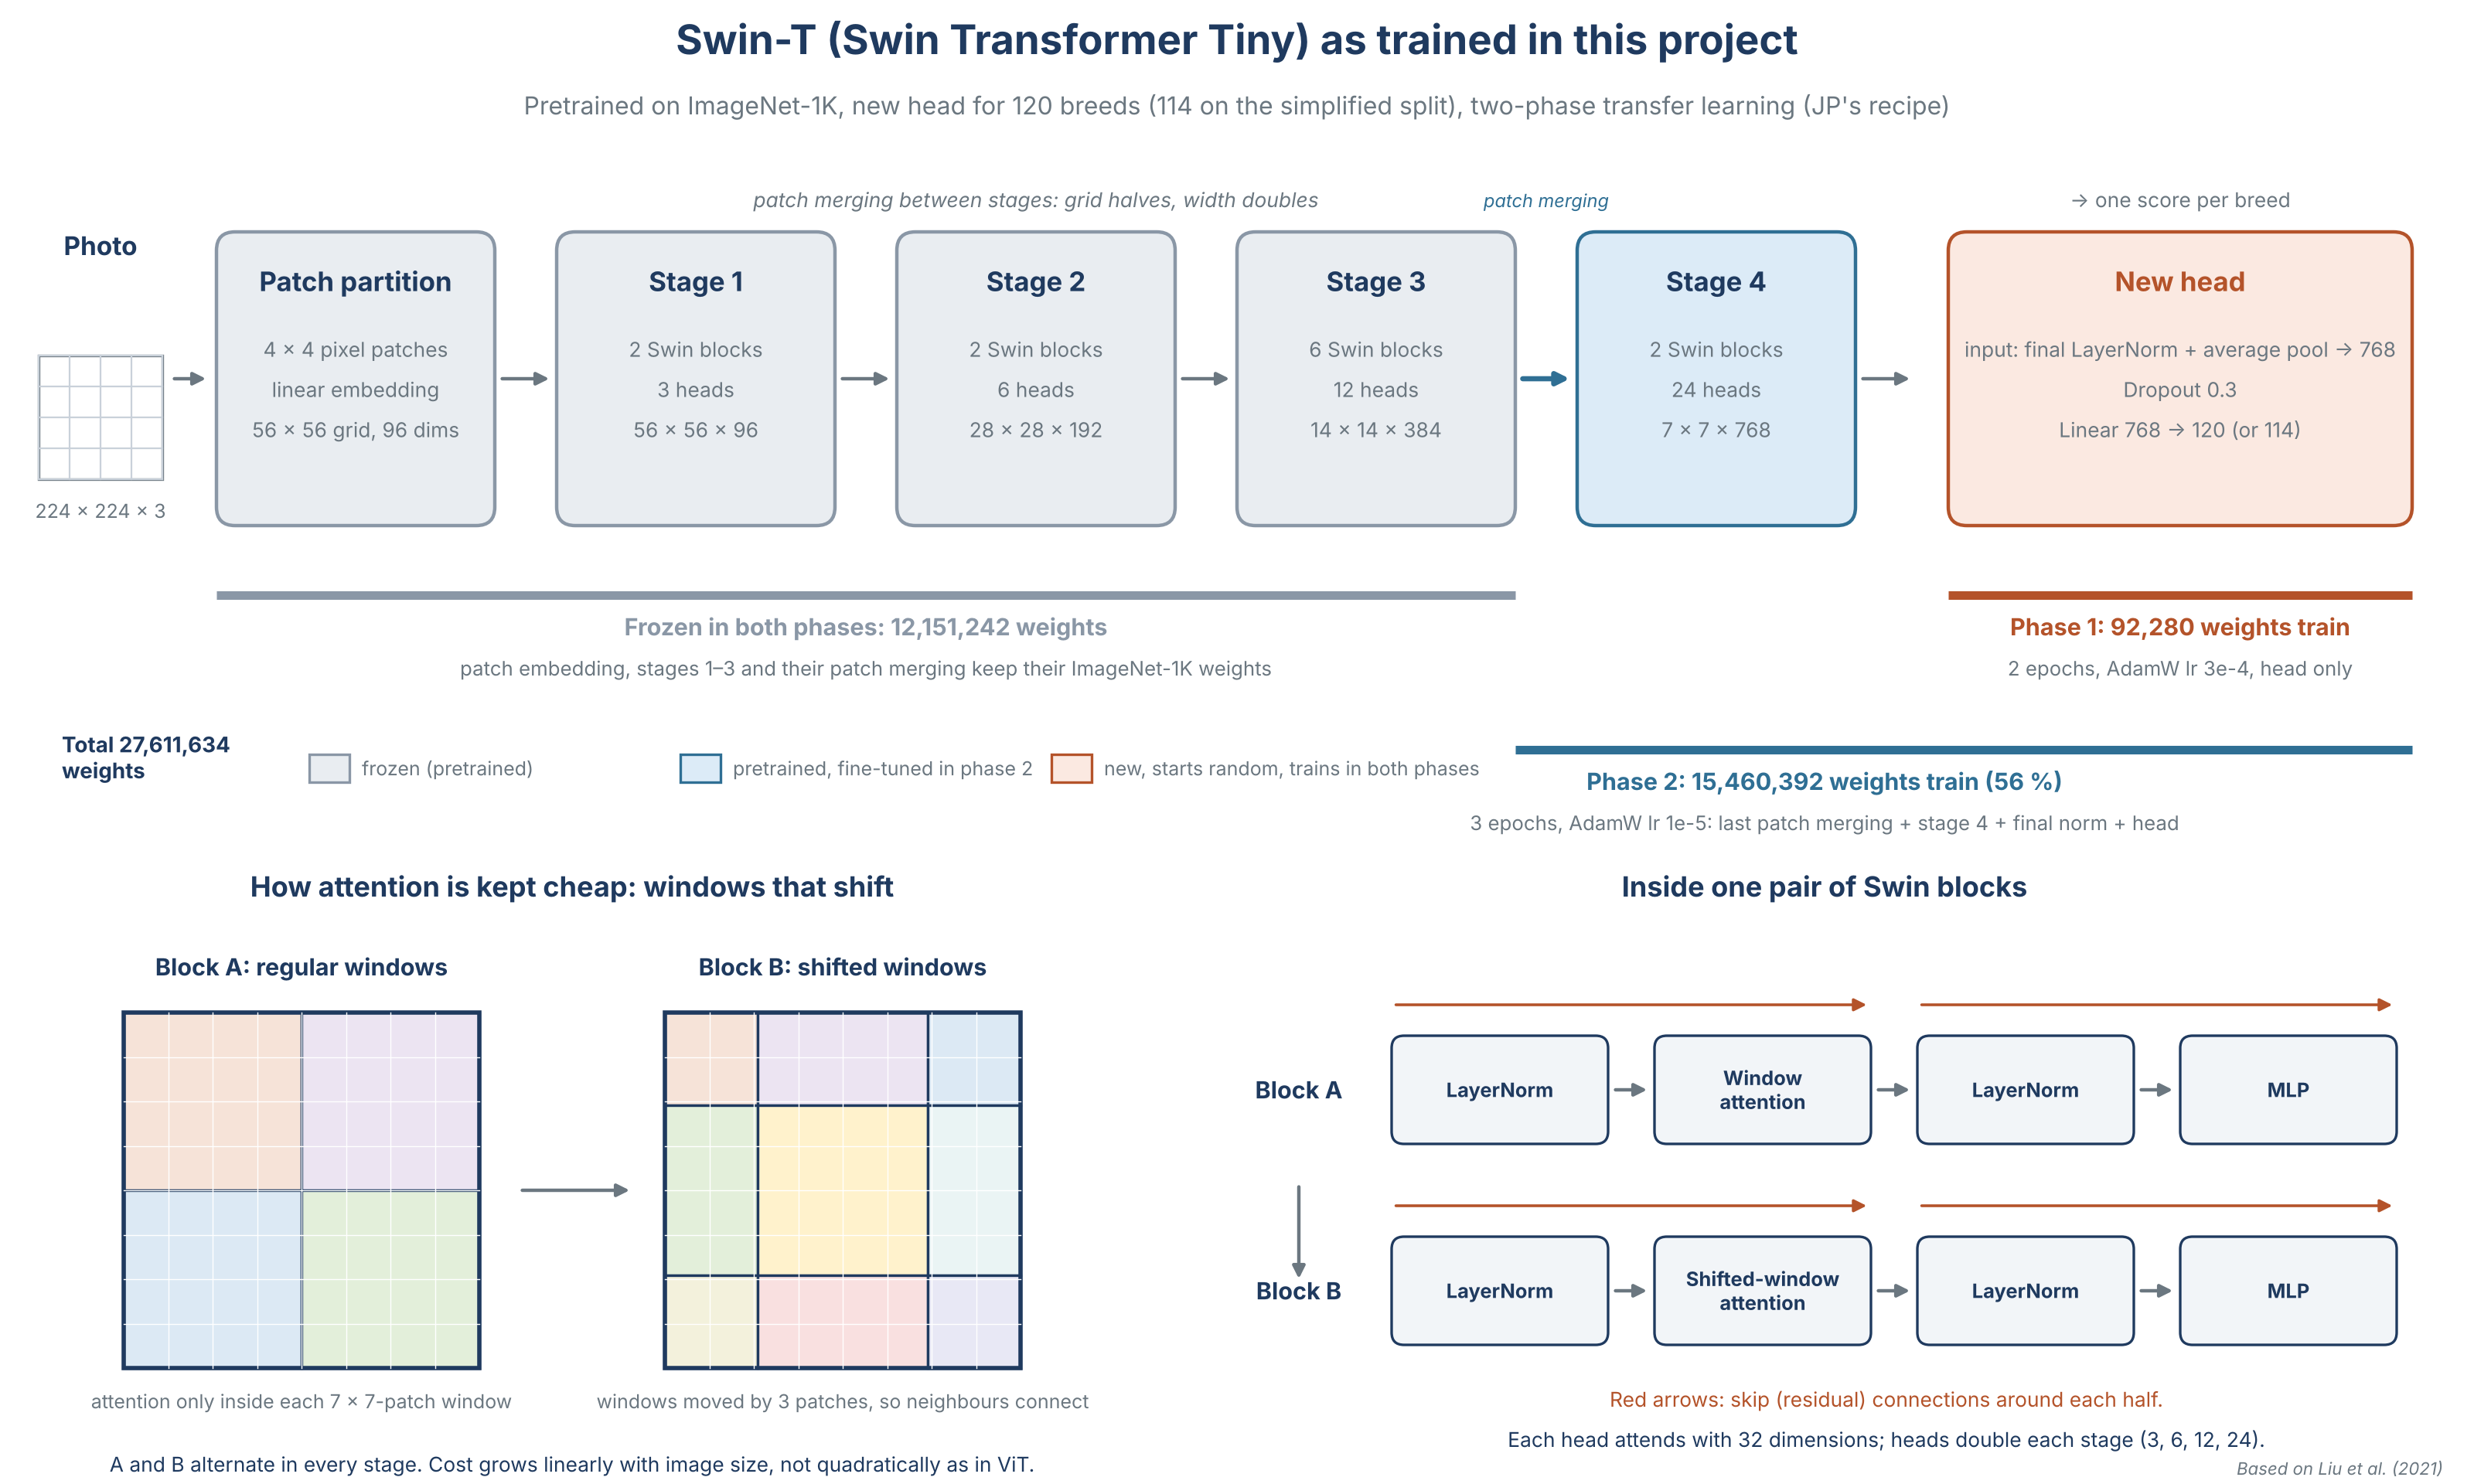

In [4]:
show(HERE / "swin_architecture.png", 900)

## 3. Training settings (JP's two-phase recipe)

Read from each run's `run_config.json`. Fixed by `train.py` and identical to
JP's EfficientNetV2-S runs: AdamW with weight decay 0.01, cosine schedule
inside each phase, cross entropy with label smoothing 0.1, 224 × 224 input,
ImageNet normalisation, training-only augmentation (horizontal flip,
rotation up to 15°, mild colour jitter), mixed precision, best epoch kept by
validation accuracy, no early stopping.

In [5]:
keys = ["model", "pretrained_weights", "manifest_path", "classes", "total_parameters",
        "head_epochs", "head_lr", "fine_tune_epochs", "fine_tune_lr", "unfreeze_from_stage",
        "batch_size", "seed", "gpu_name", "duration_minutes", "best_val_accuracy"]
cfgs = {run: load_json(RUNS / run / "run_config.json") for run in RUN_NAMES}
print(f"{'setting':<22}" + "".join(f"{run:<46}" for run in RUN_NAMES))
for k in keys:
    print(f"{k:<22}" + "".join(f"{str(cfgs[run].get(k)):<46}" for run in RUN_NAMES))

setting               unclean_transfer                              simplified_transfer                           
model                 Swin-T (Pretrained Transfer Learning)         Swin-T (Pretrained Transfer Learning)         
pretrained_weights    ImageNet-1K (Swin_T_Weights.IMAGENET1K_V1)    ImageNet-1K (Swin_T_Weights.IMAGENET1K_V1)    
manifest_path         JP_Model\split_manifest.json                  JP_Model\split_manifest_simplified.json       
classes               120                                           114                                           
total_parameters      27611634                                      27607020                                      
head_epochs           2                                             2                                             
head_lr               0.0003                                        0.0003                                        
fine_tune_epochs      3                                             3           

## 4. Training history

One row per epoch from `metrics.csv`. Validation accuracy is already about
88–90 % after the first head-only epoch, because the frozen backbone already
recognises dogs; fine-tuning stage 4 adds about another point.

Training accuracy stays *below* validation accuracy. That is expected here:
it is measured on augmented photos, with dropout on and label smoothing in
the loss, while the model is still learning. Validation loss keeps falling to
the last epoch, so there is no sign of overfitting in five epochs.

In [6]:
for run in RUN_NAMES:
    rows = load_csv(RUNS / run / "metrics.csv")
    print(f"\n{run}")
    print(f"{'epoch':>5} {'phase':<20} {'lr':>9} {'train loss':>10} {'train acc':>9} "
          f"{'val loss':>8} {'val acc':>7} {'val top5':>8} {'val F1':>7} {'sec':>6}")
    for r in rows:
        print(f"{r['epoch']:>5} {r['phase']:<20} {float(r['learning_rate']):>9.2e} {float(r['train_loss']):>10.4f} "
              f"{float(r['train_accuracy']):>8.2f}% {float(r['val_loss']):>8.4f} {float(r['val_accuracy']):>6.2f}% "
              f"{float(r['val_top5_accuracy']):>7.2f}% {float(r['val_macro_f1']):>7.4f} {float(r['seconds']):>6.1f}")


unclean_transfer
epoch phase                       lr train loss train acc val loss val acc val top5  val F1    sec
    1 Phase 1 (Head)        3.00e-04     2.8651    63.65%   1.4095  87.93%   99.40%  0.8700  110.9
    2 Phase 1 (Head)        1.65e-04     1.5341    82.57%   1.1924  89.02%   99.50%  0.8854  110.5
    3 Phase 2 (Fine-Tune)   1.00e-05     1.3333    84.18%   1.1504  89.39%   99.40%  0.8909  111.9
    4 Phase 2 (Fine-Tune)   7.52e-06     1.2946    85.66%   1.1412  89.52%   99.54%  0.8919  112.3
    5 Phase 2 (Fine-Tune)   2.58e-06     1.2738    86.29%   1.1392  89.69%   99.57%  0.8938  101.2

simplified_transfer
epoch phase                       lr train loss train acc val loss val acc val top5  val F1    sec
    1 Phase 1 (Head)        3.00e-04     2.8149    64.61%   1.3619  89.73%   99.46%  0.8923  112.6
    2 Phase 1 (Head)        1.65e-04     1.4972    83.64%   1.1528  90.40%   99.46%  0.9007  109.4
    3 Phase 2 (Fine-Tune)   1.00e-05     1.2922    85.70%   1.1150  90

unclean_transfer


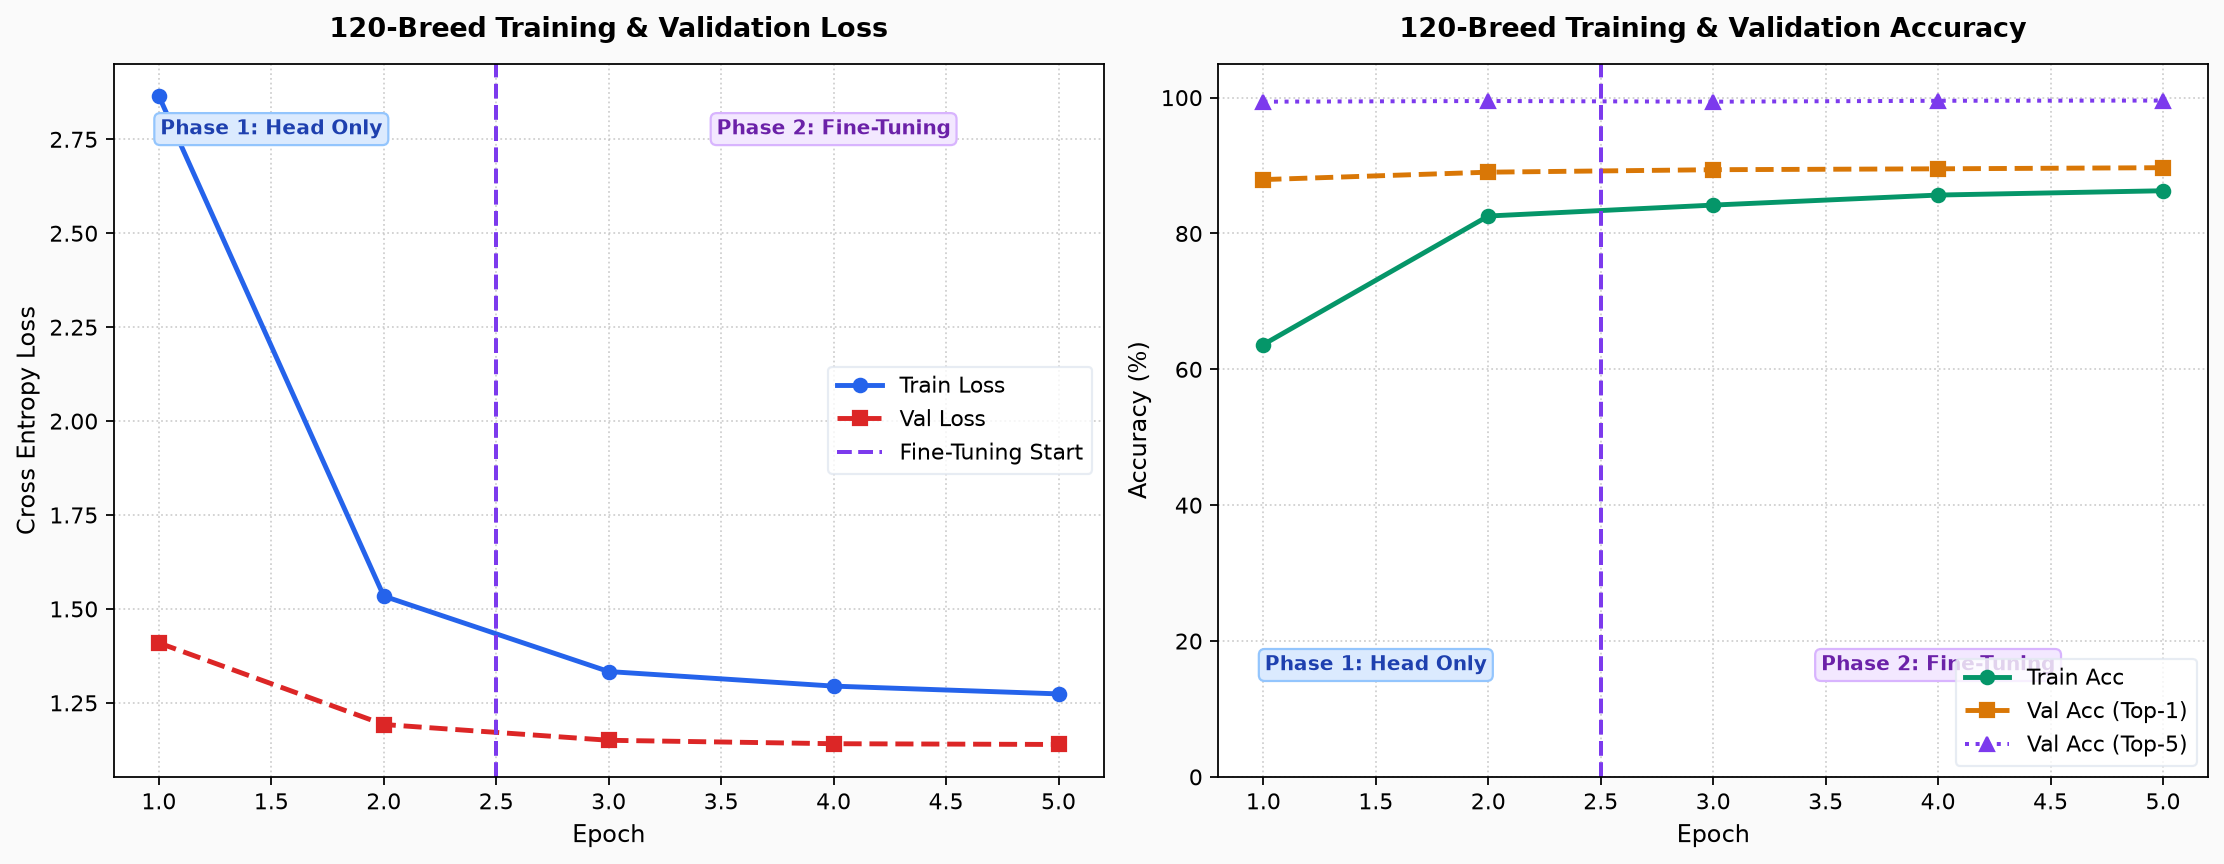

simplified_transfer


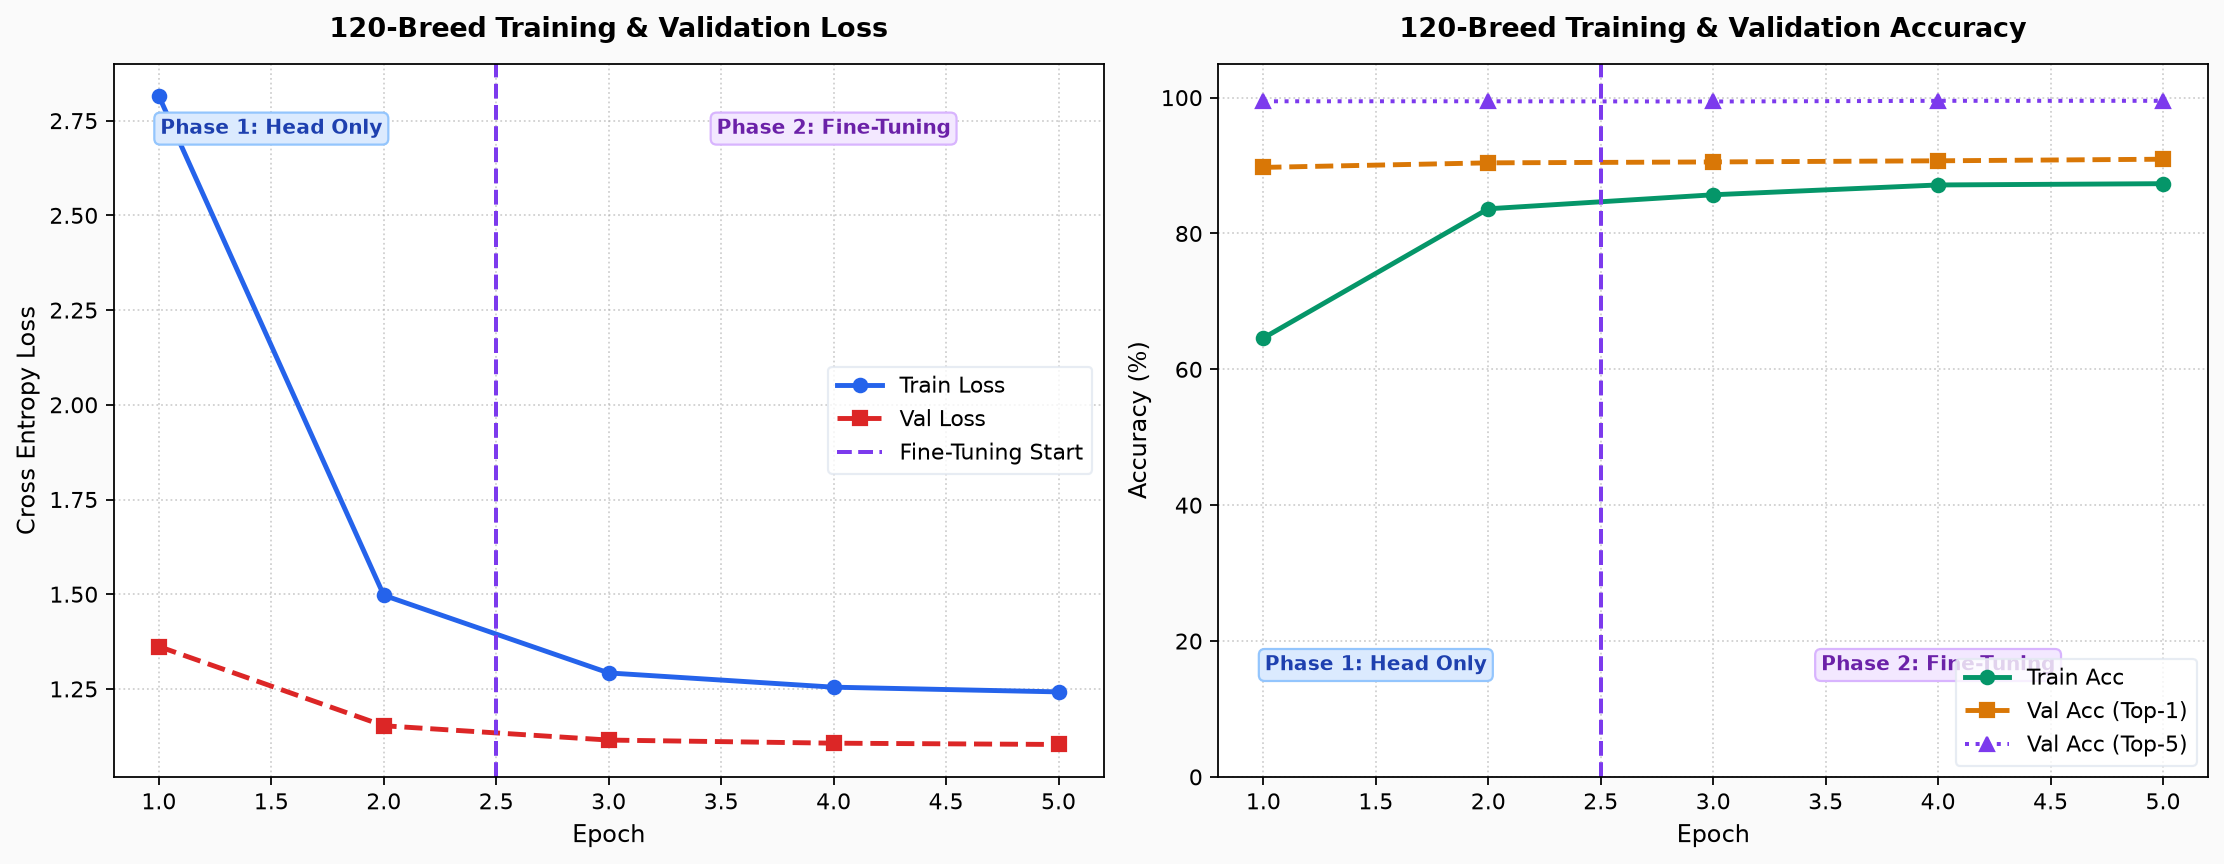

In [7]:
for run in RUN_NAMES:
    print(run)
    show(RUNS / run / "training_curves.png", 950)

Validation macro F1 per epoch for both runs (the brief asks for a
validation accuracy or F1 curve; the plots above show accuracy):

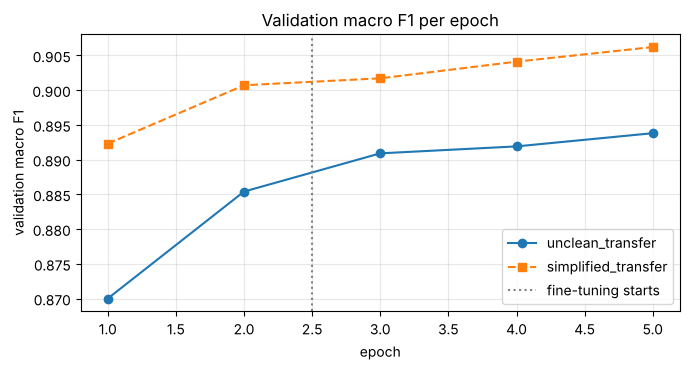

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for run, style in zip(RUN_NAMES, ["o-", "s--"]):
    rows = load_csv(RUNS / run / "metrics.csv")
    ax.plot([int(r["epoch"]) for r in rows], [float(r["val_macro_f1"]) for r in rows], style, label=run)
ax.axvline(2.5, color="grey", linestyle=":", label="fine-tuning starts")
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro F1"); ax.set_title("Validation macro F1 per epoch")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 5. Test results

`evaluate.py` scored each run once on its own test set. The unclean run was
also scored on the cleaned test set (`eval_test_clean`: the same 3,164 test
photos as the cleaned split, 120 classes), which isolates the effect of the
36 removed test photos.

In [9]:
def wilson(p, n, z=1.96):
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    margin = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return 100*(centre-margin), 100*(centre+margin)

evals = [("unclean_transfer", "eval_test"), ("unclean_transfer", "eval_test_clean"),
         ("simplified_transfer", "eval_test")]
print(f"{'run / evaluation':<38} {'photos':>6} {'cls':>4} {'top-1':>7} {'95% interval':>15} "
      f"{'top-5':>7} {'macro P':>8} {'macro R':>8} {'macro F1':>8}")
for run, ev in evals:
    m = load_json(RUNS / run / ev / "metrics.json")
    lo, hi = wilson(m["top1_accuracy"] / 100, m["test_samples"])
    print(f"{run + ' / ' + ev:<38} {m['test_samples']:>6} {m['total_classes']:>4} {m['top1_accuracy']:>6.2f}% "
          f"{lo:>6.2f}–{hi:<6.2f}% {m['top5_accuracy']:>6.2f}% {m['macro_precision']:>7.2f}% "
          f"{m['macro_recall']:>7.2f}% {m['macro_f1']:>8.4f}")

run / evaluation                       photos  cls   top-1    95% interval   top-5  macro P  macro R macro F1
unclean_transfer / eval_test             3200  120  88.03%  86.86–89.11 %  99.31%   88.28%   87.69%   0.8747
unclean_transfer / eval_test_clean       3164  120  88.21%  87.04–89.29 %  99.30%   88.46%   87.82%   0.8764
simplified_transfer / eval_test          3164  114  89.92%  88.82–90.92 %  99.34%   90.17%   89.63%   0.8953


In [10]:
for run in RUN_NAMES:
    print((RUNS / run / "eval_test" / "metrics_summary.txt").read_text(encoding="utf-8"))

ITRI626 EVALUATION SUMMARY - RUN: unclean_transfer
Architecture:           Transfer-Swin-T
Manifest Evaluated:     JP_Model\split_manifest.json
Total Test Samples:     3200 (120 classes)
Trainable Parameters:   27,611,634
Hardware Used:          NVIDIA GeForce RTX 4060 Laptop GPU
Training Time:          9.13 minutes

CORE TEST METRICS:
  * Top-1 Test Accuracy:   88.03%
  * Top-5 Test Accuracy:   99.31%
  * Macro-Averaged F1:     0.8747 (87.47%)
  * Macro Precision:       88.28%
  * Macro Recall:          87.69%
  * Inference Latency:     0.43 ms / image

Artifacts Written to: C:\Github\Dog_Classifier\Sulaiman_Model\results\runs\unclean_transfer\eval_test
  - metrics.json
  - confusion_matrix.png
  - confusion_matrix.csv
  - per_class_metrics.csv
  - sample_predictions.png

ITRI626 EVALUATION SUMMARY - RUN: simplified_transfer
Architecture:           Transfer-Swin-T
Manifest Evaluated:     JP_Model\split_manifest_simplified.json
Total Test Samples:     3164 (114 classes)
Trainable Param

## 6. Confusion matrices

unclean_transfer


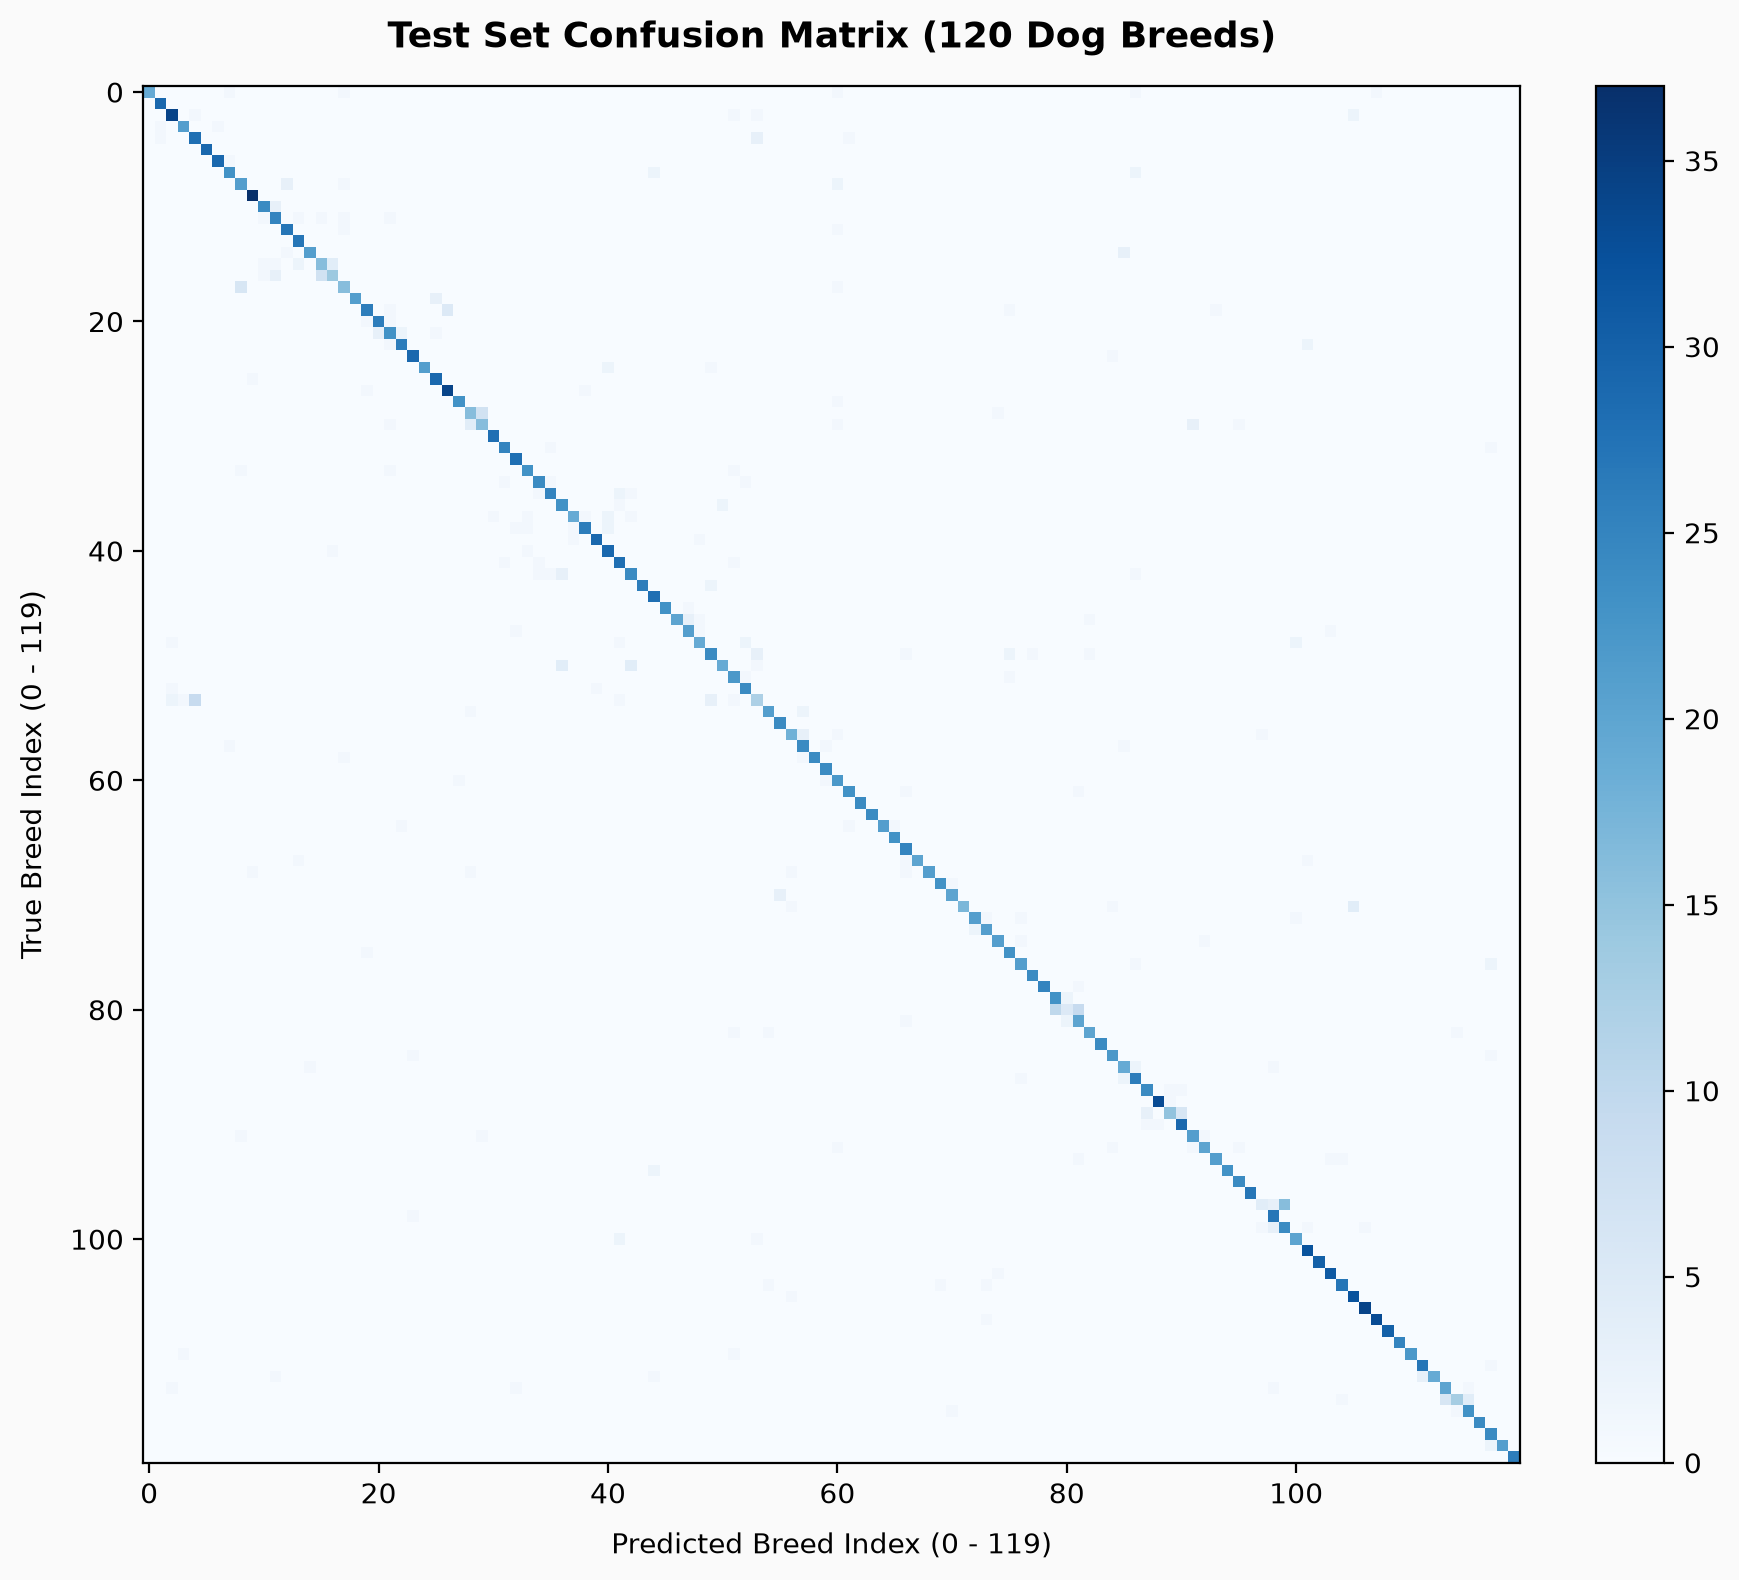

simplified_transfer


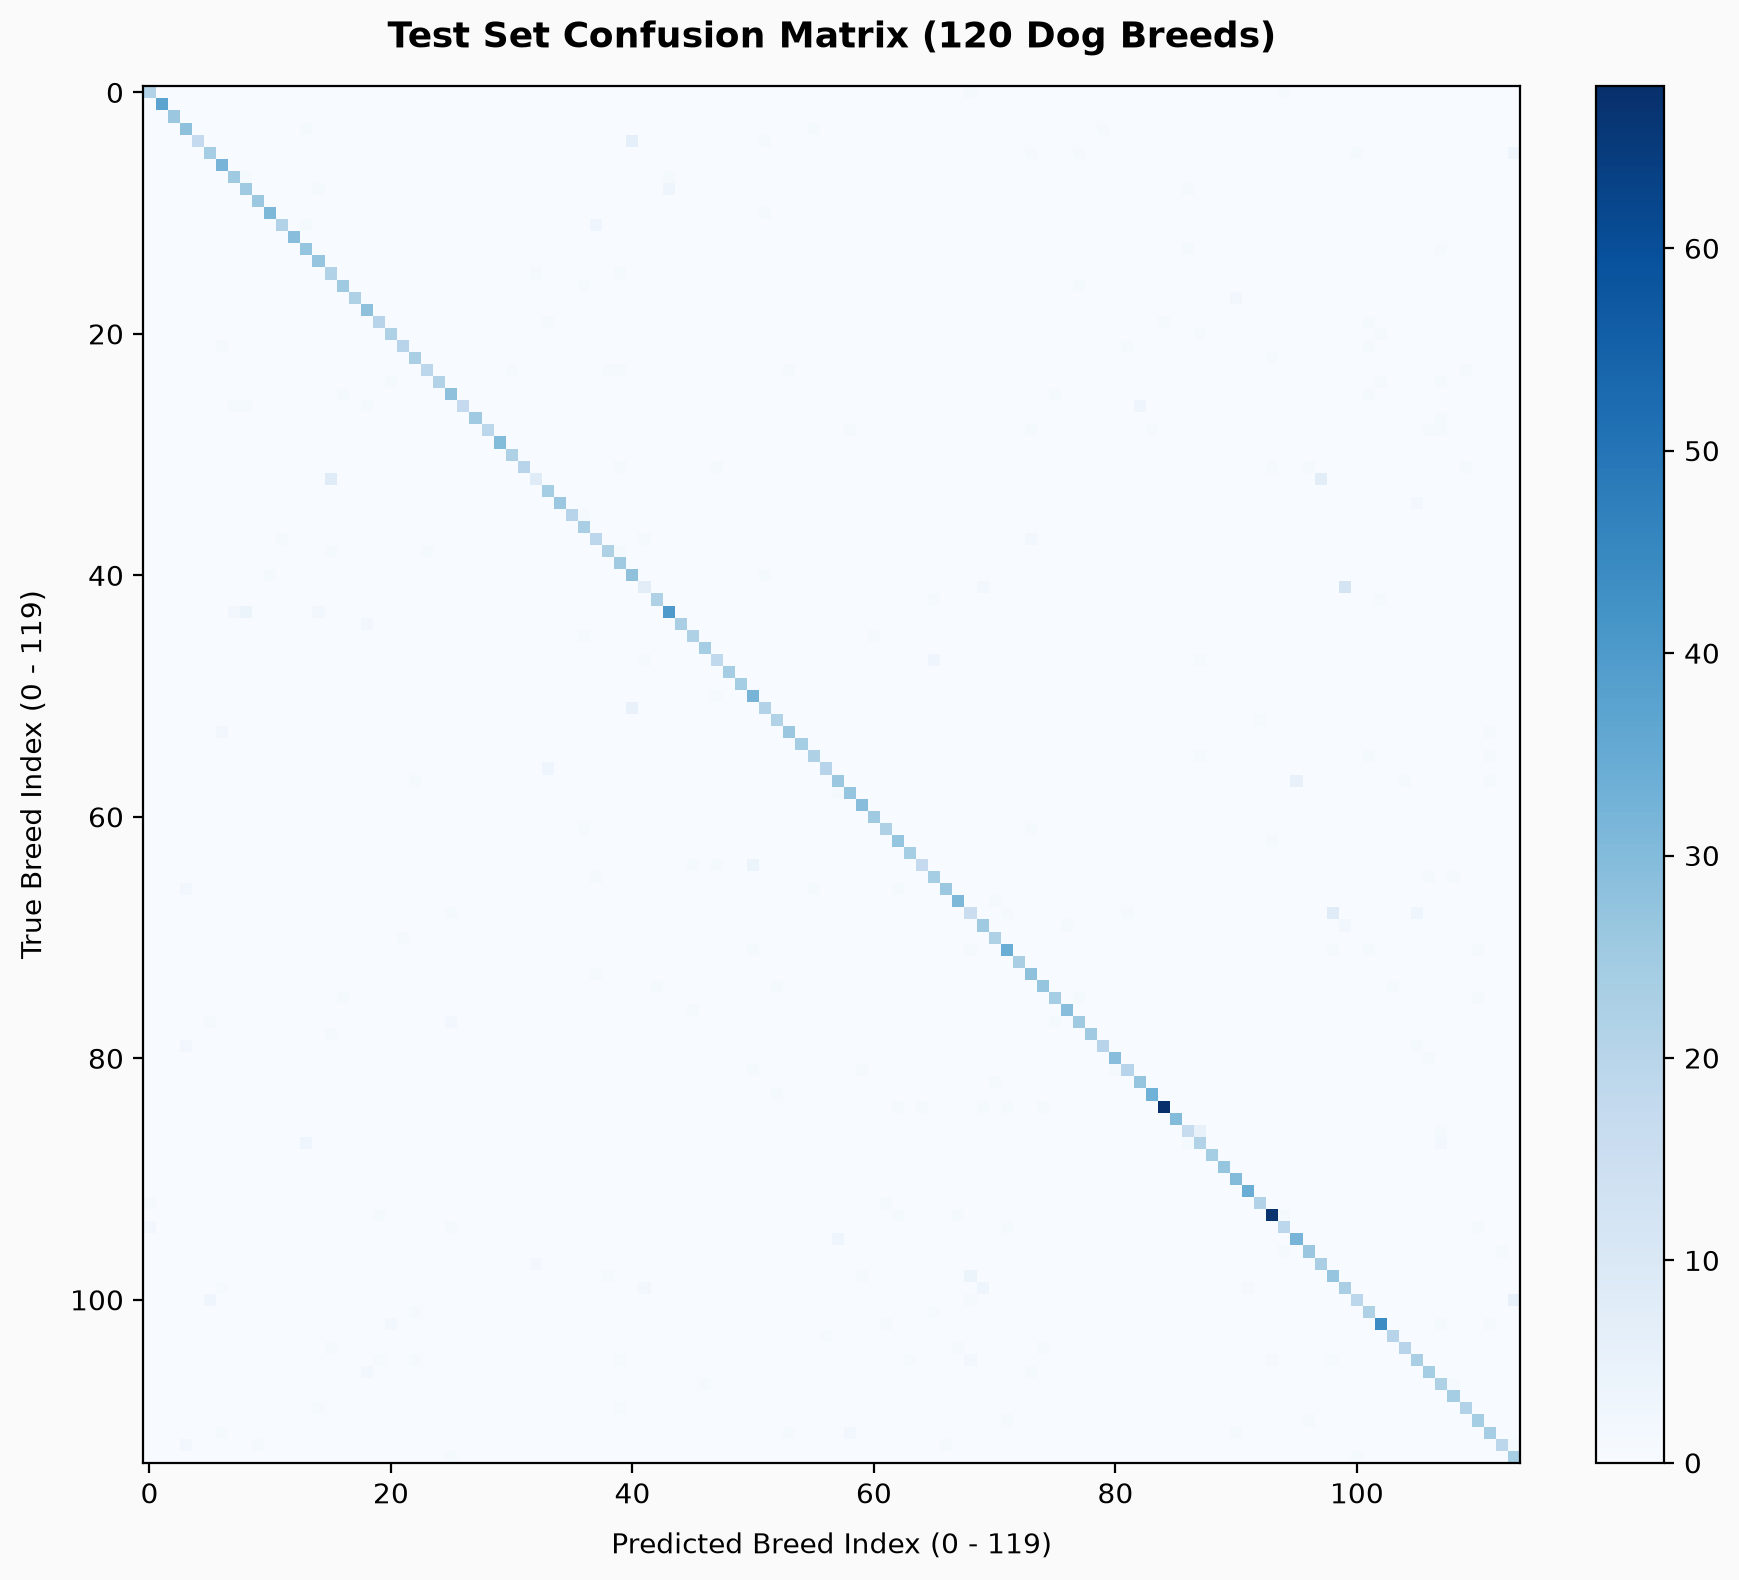

In [11]:
for run in RUN_NAMES:
    print(run)
    show(RUNS / run / "eval_test" / "confusion_matrix.png", 700)

The heat maps are too dense to read breed by breed, so the most frequent
off-diagonal cells are listed below. They are almost all pairs of breeds
that look alike.

In [12]:
def top_confusions(run, n=12):
    names = [r["breed_name"] for r in load_csv(RUNS / run / "eval_test" / "per_class_metrics.csv")]
    cm = np.loadtxt(RUNS / run / "eval_test" / "confusion_matrix.csv", delimiter=",", dtype=int)
    pairs = [(cm[i, j], names[i], names[j]) for i in range(len(names)) for j in range(len(names))
             if i != j and cm[i, j]]
    pairs.sort(reverse=True)
    errors = cm.sum() - np.trace(cm)
    print(f"\n{run}: {errors} errors out of {cm.sum()} test photos")
    for count, true, pred in pairs[:n]:
        print(f"  {true:<32} predicted as {pred:<32} {count:>3}")

for run in RUN_NAMES:
    top_confusions(run)


unclean_transfer: 383 errors out of 3200 test photos
  Eskimo Dog                       predicted as Siberian Husky                    16
  Collie                           predicted as Shetland Sheepdog                 10
  Lhasa                            predicted as Shih-Tzu                           9
  Collie                           predicted as Border Collie                      9
  Staffordshire Bullterrier        predicted as American Staffordshire Terrier     7
  English Foxhound                 predicted as Walker Hound                       7
  Redbone                          predicted as Rhodesian Ridgeback                6
  Miniature Poodle                 predicted as Toy Poodle                         6
  Appenzeller                      predicted as Entlebucher                        6
  Irish Wolfhound                  predicted as Scottish Deerhound                 5
  Walker Hound                     predicted as English Foxhound                   4
  Silky Ter

## 7. Per-breed metrics

All breeds are in `eval_test/per_class_metrics.csv`. The weakest and
strongest by F1:

In [13]:
for run in RUN_NAMES:
    rows = load_csv(RUNS / run / "eval_test" / "per_class_metrics.csv")
    ranked = sorted(rows, key=lambda r: float(r["f1_score"]))
    print(f"\n{run}: {sum(float(r['f1_score']) == 1.0 for r in rows)} breeds with F1 = 1.0, "
          f"{sum(float(r['f1_score']) < 0.7 for r in rows)} below 0.7")
    print(f"  {'weakest':<32} {'prec':>6} {'recall':>6} {'F1':>6} {'n':>4}")
    for r in ranked[:8]:
        print(f"  {r['breed_name']:<32} {float(r['precision']):>6.3f} {float(r['recall']):>6.3f} "
              f"{float(r['f1_score']):>6.3f} {r['support']:>4}")
    print(f"  {'strongest':<32}")
    for r in ranked[-5:][::-1]:
        print(f"  {r['breed_name']:<32} {float(r['precision']):>6.3f} {float(r['recall']):>6.3f} "
              f"{float(r['f1_score']):>6.3f} {r['support']:>4}")


unclean_transfer: 10 breeds with F1 = 1.0, 9 below 0.7
  weakest                            prec recall     F1    n
  Eskimo Dog                        0.667  0.174  0.276   23
  Collie                            0.556  0.208  0.303   24
  Lhasa                             0.571  0.414  0.480   29
  English Foxhound                  0.737  0.560  0.636   25
  American Staffordshire Terrier    0.667  0.615  0.640   26
  Walker Hound                      0.667  0.667  0.667   24
  Miniature Poodle                  0.867  0.542  0.667   24
  Siberian Husky                    0.600  0.800  0.686   30
  strongest                       
  African Hunting Dog               1.000  1.000  1.000   26
  Mexican Hairless                  1.000  1.000  1.000   24
  Keeshond                          1.000  1.000  1.000   25
  Chow                              1.000  1.000  1.000   30
  Pug                               1.000  1.000  1.000   30

simplified_transfer: 11 breeds with F1 = 1.0, 4 below 

**Eskimo Dog** is the weakest breed in both runs: most of its test photos
are called Siberian Husky. **Collie** is mostly confused with Shetland
Sheepdog and Border Collie, and **Lhasa** with Shih-Tzu. These are genuinely
similar breeds, and Stanford Dogs is known to contain some mislabelled
photos in exactly these groups.

## 8. Correct and incorrect predictions

JP's `evaluate.py` saves the first 12 test photos with their predictions
(green = correct, red = misclassified).

unclean_transfer


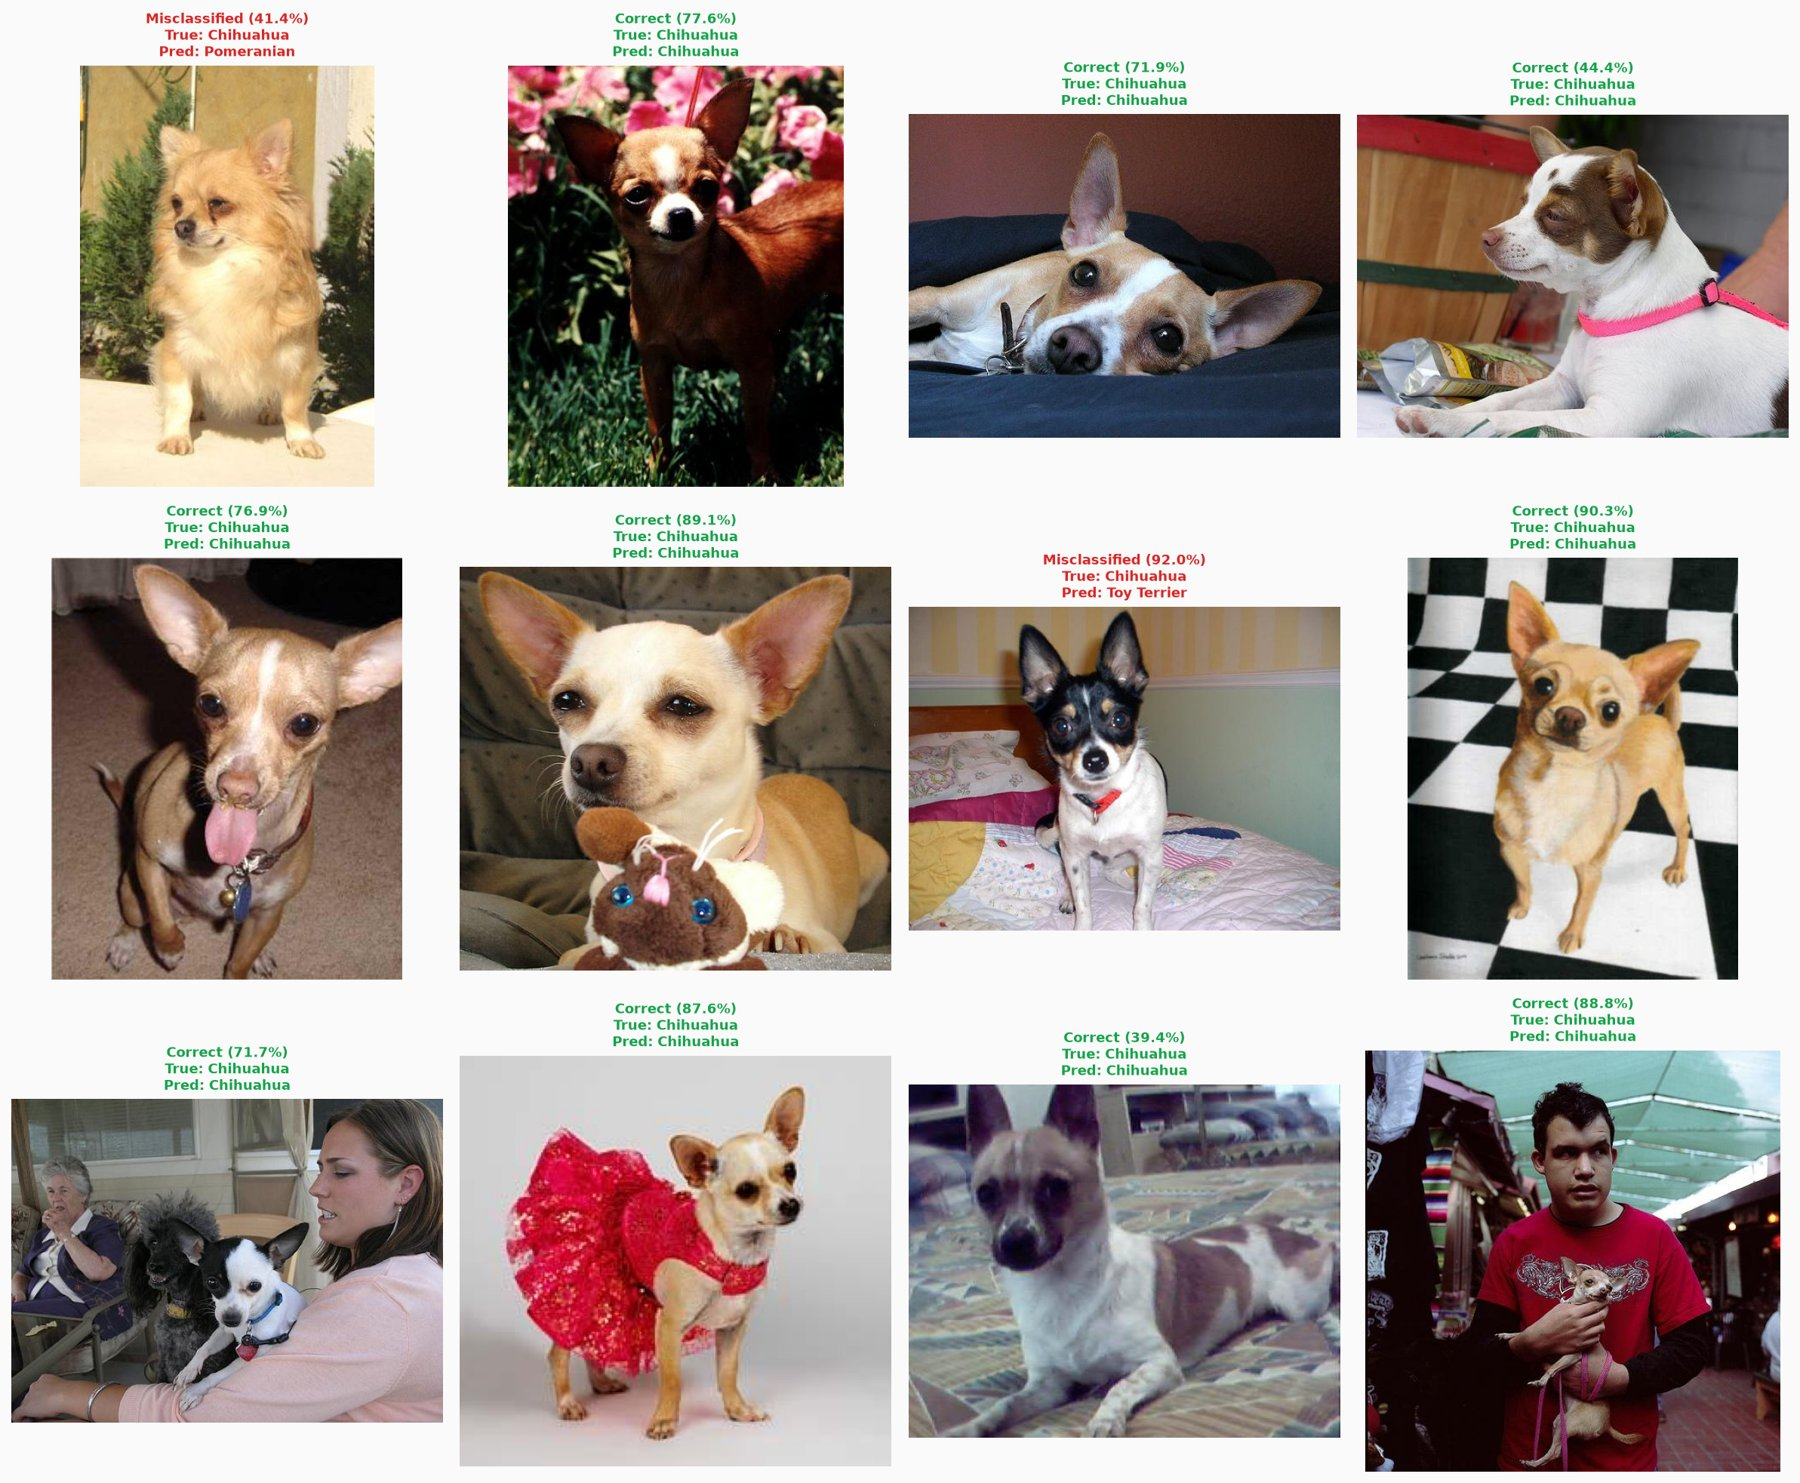

simplified_transfer


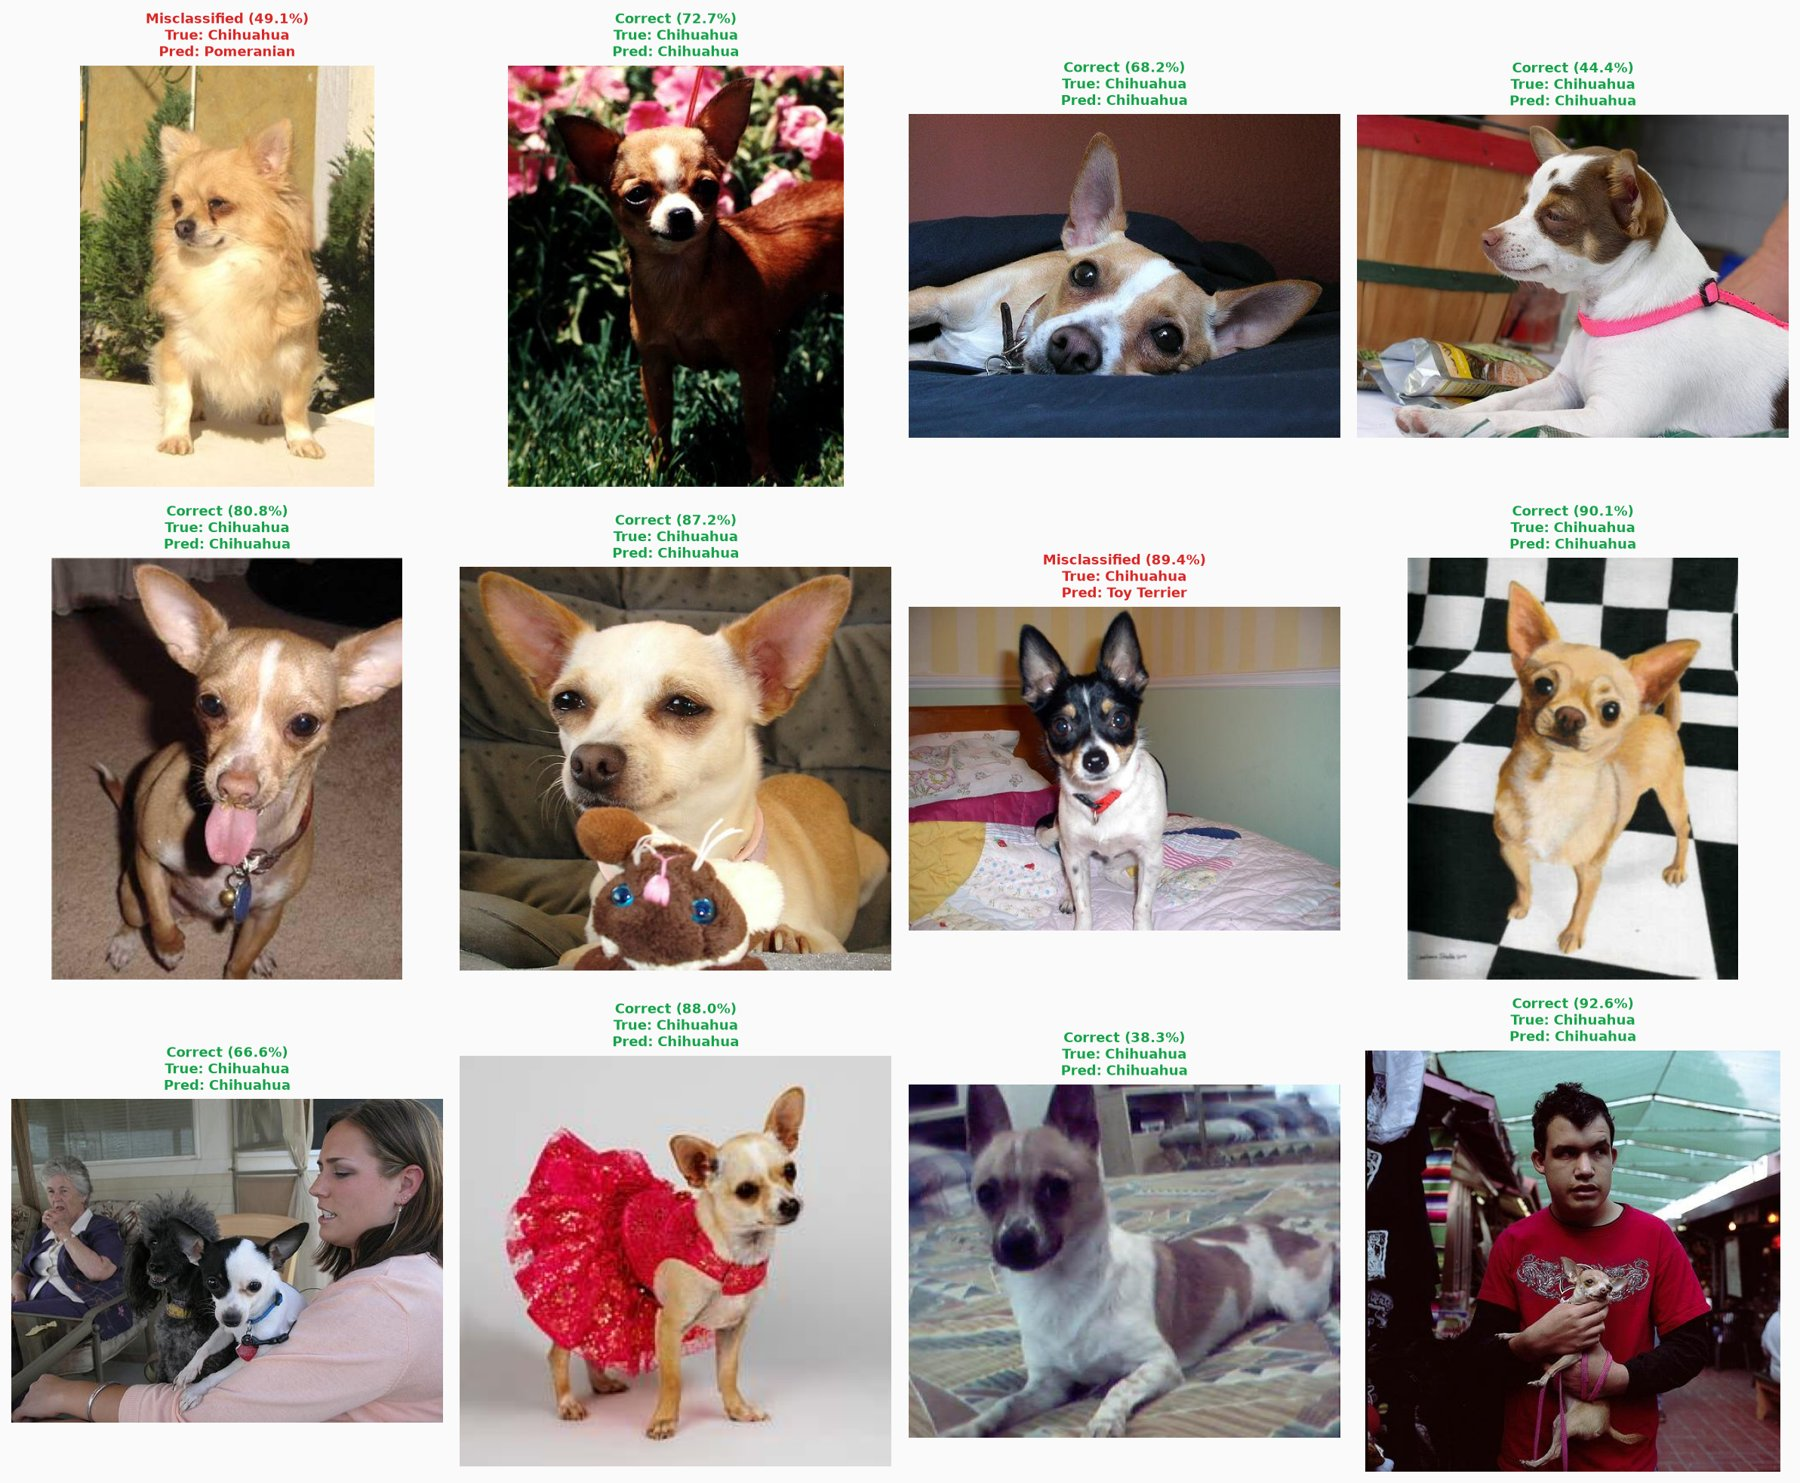

In [14]:
for run in RUN_NAMES:
    print(run)
    show(RUNS / run / "eval_test" / "sample_predictions.png", 900)

## 9. What merging and cleaning changed

The simplified run scores higher, but its test set is easier by
construction: the merged breeds can no longer be confused with each other.
The table compares the merged breeds in the unclean run with their merged
class in the simplified run.

In [15]:
unclean = {r["breed_name"]: float(r["f1_score"]) for r in load_csv(RUNS / "unclean_transfer" / "eval_test" / "per_class_metrics.csv")}
simple = {r["breed_name"]: float(r["f1_score"]) for r in load_csv(RUNS / "simplified_transfer" / "eval_test" / "per_class_metrics.csv")}
for g in merged["merged_groups_applied"]:
    parts = ", ".join(f"{b} {unclean[b]:.3f}" for b in g["breeds"])
    print(f"{g['target_name']:<22} unclean F1: {parts}")
    print(f"{'':<22} simplified F1: {simple[g['target_name']]:.3f}\n")

a = load_json(RUNS / "unclean_transfer" / "eval_test_clean" / "metrics.json")
b = load_json(RUNS / "simplified_transfer" / "eval_test" / "metrics.json")
print(f"Same 3,164 test photos: 120 classes {a['top1_accuracy']:.2f}% (F1 {a['macro_f1']:.4f}) "
      f"vs 114 classes {b['top1_accuracy']:.2f}% (F1 {b['macro_f1']:.4f})")

Staffordshire Terrier  unclean F1: Staffordshire Bullterrier 0.696, American Staffordshire Terrier 0.640
                       simplified F1: 0.917

Foxhound               unclean F1: English Foxhound 0.636, Walker Hound 0.667
                       simplified F1: 0.870

Poodle                 unclean F1: Toy Poodle 0.800, Miniature Poodle 0.667, Standard Poodle 0.868
                       simplified F1: 0.958

Schnauzer              unclean F1: Miniature Schnauzer 0.979, Standard Schnauzer 0.857, Giant Schnauzer 0.889
                       simplified F1: 0.944

Same 3,164 test photos: 120 classes 88.21% (F1 0.8764) vs 114 classes 89.92% (F1 0.8953)


## 10. Comparison with JP's EfficientNetV2-S, Lindani's CNN and the earlier Swin-T run

JP's runs use the same pipeline, the same split files and the same recipe,
so the Swin-T vs EfficientNetV2-S rows differ only in the architecture.
Lindani's CNN is trained from scratch with its own recipe on the original
split. The earlier Swin-T run used a different pipeline (full fine-tuning,
15 epochs, learning rate 1e-4) and is shown for reference only.

In [16]:
JP = REPO / "JP_Model" / "results" / "runs"
rows = [
    ("Swin-T (Sulaiman), unclean",          RUNS / "unclean_transfer" / "eval_test" / "metrics.json"),
    ("Swin-T (Sulaiman), simplified",       RUNS / "simplified_transfer" / "eval_test" / "metrics.json"),
    ("EfficientNetV2-S (JP), unclean",      JP / "unclean_transfer" / "eval_test" / "metrics.json"),
    ("EfficientNetV2-S (JP), simplified",   JP / "simplified_transfer" / "eval_test" / "metrics.json"),
]
print(f"{'model / split':<38} {'top-1':>7} {'95% interval':>15} {'top-5':>7} {'macro F1':>8} {'params (total)':>15} {'train min':>9}")
for label, p in rows:
    m = load_json(p)
    lo, hi = wilson(m["top1_accuracy"] / 100, m["test_samples"])
    print(f"{label:<38} {m['top1_accuracy']:>6.2f}% {lo:>6.2f}–{hi:<6.2f}% {m['top5_accuracy']:>6.2f}% "
          f"{m['macro_f1']:>8.4f} {m['trainable_parameters']/1e6:>14.1f}M {m['training_time_minutes']:>9.2f}")

lin = load_json(REPO / "Lindani_Model" / "results" / "runs" / "iter2_deeper" / "eval_test" / "metrics.json")
print(f"{'Baseline CNN (Lindani), unclean':<38} {100*lin['accuracy']:>6.2f}% {'':>15} "
      f"{100*lin['top5_accuracy']:>6.2f}% {lin['macro_f1']:>8.4f}   (trained from scratch)")

old = load_json(HERE / "previous_run_lindani_pipeline" / "results" / "runs" / "swin_t" / "eval_test" / "metrics.json")
print(f"{'Swin-T earlier run (other pipeline)':<38} {100*old['accuracy']:>6.2f}% {'':>15} "
      f"{100*old['top5_accuracy']:>6.2f}% {old['macro_f1']:>8.4f}   (reference only)")

model / split                            top-1    95% interval   top-5 macro F1  params (total) train min
Swin-T (Sulaiman), unclean              88.03%  86.86–89.11 %  99.31%   0.8747           27.6M      9.13
Swin-T (Sulaiman), simplified           89.92%  88.82–90.92 %  99.34%   0.8953           27.6M      9.09
EfficientNetV2-S (JP), unclean          83.12%  81.78–84.38 %  97.75%   0.8254           20.3M     14.74
EfficientNetV2-S (JP), simplified       84.54%  83.24–85.76 %  97.79%   0.8402           20.3M     16.23
Baseline CNN (Lindani), unclean         53.84%                  84.78%   0.5320   (trained from scratch)
Swin-T earlier run (other pipeline)     85.38%                  98.56%   0.8490   (reference only)


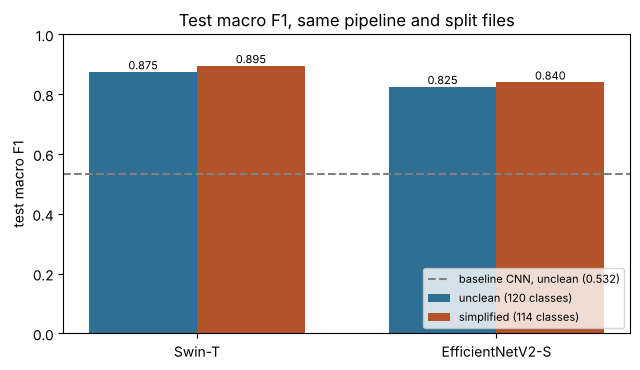

In [17]:
labels = ["Swin-T", "EfficientNetV2-S"]
u = [load_json(RUNS / "unclean_transfer" / "eval_test" / "metrics.json")["macro_f1"],
     load_json(JP / "unclean_transfer" / "eval_test" / "metrics.json")["macro_f1"]]
s = [load_json(RUNS / "simplified_transfer" / "eval_test" / "metrics.json")["macro_f1"],
     load_json(JP / "simplified_transfer" / "eval_test" / "metrics.json")["macro_f1"]]
x = np.arange(len(labels)); w = 0.36
fig, ax = plt.subplots(figsize=(6.5, 3.8))
b1 = ax.bar(x - w/2, u, w, label="unclean (120 classes)", color="#2F6F94")
b2 = ax.bar(x + w/2, s, w, label="simplified (114 classes)", color="#B4532A")
ax.bar_label(b1, fmt="%.3f", fontsize=8); ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.axhline(lin["macro_f1"], color="grey", linestyle="--", label=f"baseline CNN, unclean ({lin['macro_f1']:.3f})")
ax.set_xticks(x, labels); ax.set_ylim(0, 1); ax.set_ylabel("test macro F1")
ax.set_title("Test macro F1, same pipeline and split files"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 11. Conclusions

- **Swin-T beats EfficientNetV2-S on both split files** under an identical
  pipeline: 88.0 % vs 83.1 % test accuracy (macro F1 0.875 vs 0.825) on the
  unclean split, and 89.9 % vs 84.5 % (0.895 vs 0.840) on the simplified
  split. The 95 % intervals do not overlap, so the gap is not noise from
  the test sample.
- **Cleaning the test set barely matters** (88.03 % → 88.21 % on the same
  model). **Merging look-alike breeds helps more** (88.21 % → 89.92 % on the
  same photos), mostly because the poodles, schnauzers, Staffordshires and
  foxhounds can no longer be confused with each other.
- **The remaining errors are look-alike breeds**: Eskimo Dog vs Siberian
  Husky, Collie vs Shetland Sheepdog and Border Collie, Lhasa vs Shih-Tzu.
- **The lighter two-phase recipe did better than the earlier full
  fine-tune** (88.0 % vs 85.4 %, 5 epochs vs 15). Keeping stages 1–3 frozen
  preserves more of the ImageNet features.
- **Caveat:** Stanford Dogs was built from ImageNet, and Swin-T was
  pretrained on ImageNet-1K, so the backbone has very likely seen many of
  these test photos. That makes the absolute scores optimistic for all the
  pretrained models, and it may be part of why freezing more of the backbone
  helped. Lindani's from-scratch CNN (53.8 %) is the only score free of this
  effect.